# Análise de Campanha do Banco XPTOKW

# Objetivos

- Realizar uma **Análise Exploratória** buscando por insights sobre a venda dos títulos e perfil dos clientes;
- Responder a perguntas específicas da área de negócio;
- Construir um **Relatório Técnico** para a linguagem de negócios abordando os insights encontrados com base nos dados.

In [2]:
# Imports
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import sqrt
from scipy.stats import beta, t

# adiciona diretório raiz do projeto ao sys.path
sys.path.insert(0, str(Path.cwd().parent))

# configurações gerais
pd.set_option('display.max_rows', None)
sns.set_theme(style='whitegrid', palette='pastel')
%matplotlib inline


# 1. Carga dos Dados

In [3]:
data_path = Path.cwd().parent / 'data' / 'bank_marketing.xlsx'

raw_data = pd.read_excel(
    data_path,
    sheet_name='bank_marketing',
    engine='openpyxl',
    header=1,                       # ignora a primeira linha do arquivo, que contém células em branco
    usecols='B:K'                   # ajusta o range de colunas para corresponder ao dataset
)

print(f"Dataset carregado de: {data_path}")
print("\n========= Dimensões do Dataset =========\n")
print(f"Número de Linhas: {raw_data.shape[0]}")
print(f"Número de Colunas: {raw_data.shape[1]}")
raw_data.head()

Dataset carregado de: c:\Users\jooar\ds\LABS\data-analisys-labs\data-analisys-labs\projects\bank-marketing-analytics\data\bank_marketing.xlsx

========= Dimensões do Dataset =========

Número de Linhas: 9684
Número de Colunas: 10


,Cliente_Comprou_o_Titulo?,Idade,Profissão,Estado_Civil,Formação,Cliente_Devedor?,Saldo_Conta_Corrente,Tem_Hipoteca?,Tem_Emprestimo?,Qte_de_Ligações_Feitas
0,Não,33,Operário,Casado,Ensino Médio,Não,263,Sim,Não,3
1,Não,58,Aposentado,Casado,Ensino Médio,Não,19,Não,Sim,3
2,Sim,83,Aposentado,Casado,Fundamental,Não,425,Não,Não,1
3,Sim,32,Administrador,Solteiro,Ensino Superior,Não,10281,Não,Não,1
4,Sim,31,Administrador,Solteiro,Ensino Médio,Não,360,Sim,Não,1


## 1.1 Visão Geral do Dataset

Cada linha do dataset representa um cliente, desse modo temos **9684 clientes cadastrados** nessa base. Antes de seguirmos com as análises é importante fazer uma verificação na qualidade dos dados (**Sanity Check**), vamos verificar:
- a presença de dados duplicados;
- verificar se há dados nulos ou inválidos;
- a presença de outliers.

In [4]:
# informações gerais sobre o dataset
print("========= Informações do Dataset =========\n")
raw_data.info()

print("\n========= Dados Duplicados =========")
dados_duplicados = raw_data.duplicated().sum()
print(f"Número de linhas duplicadas: {dados_duplicados}")



========= Informações do Dataset =========

<class 'pandas.DataFrame'>
RangeIndex: 9684 entries, 0 to 9683
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Cliente_Comprou_o_Titulo?  9684 non-null   str  
 1   Idade                      9684 non-null   int64
 2   Profissão                  9684 non-null   str  
 3   Estado_Civil               9684 non-null   str  
 4   Formação                   9684 non-null   str  
 5   Cliente_Devedor?           9684 non-null   str  
 6   Saldo_Conta_Corrente       9684 non-null   int64
 7   Tem_Hipoteca?              9684 non-null   str  
 8   Tem_Emprestimo?            9684 non-null   str  
 9   Qte_de_Ligações_Feitas     9684 non-null   int64
dtypes: int64(3), str(7)
memory usage: 756.7 KB

========= Dados Duplicados =========
Número de linhas duplicadas: 278


Não foram identificados valores nulos na base de dados. Entretanto, foram encontrados **278 registros duplicados**.

Considerando a premissa do estudo de caso de que cada linha representa um cliente distinto, a presença desses registros pode indicar inconsistências na base.

Dessa forma, assumindo que os registros duplicados correspondam a repetições indevidas dos mesmos clientes, optou-se por removê-los, a fim de evitar a super representação de determinadas observações e possíveis distorções nas análises estatísticas.

Seguindo na investigação, ainda precisamos conferir se há valores inválidos e outliers na nossa base.

In [5]:
num_vars = [col for col in raw_data.columns if raw_data[col].dtype == 'int64']
cat_vars = [col for col in raw_data.columns if raw_data[col].dtype == 'str']

print("=========== Granularidade das Variáveis Categóricas ===========\n")
print(raw_data[cat_vars].nunique())
print('\n========= Valores Únicos das Variáveis Categóricas =========\n')
for var in cat_vars:
    print(f"{var}: {raw_data[var].unique().tolist()}")

print("\n=========== Estatísticas Descritivas das Variáveis Numéricas ===========\n")
print(raw_data[num_vars].describe())


print("\n=========== Percentual de Outliers nas Variáveis Numéricas ===========\n")
for var in num_vars:
    Q1 = raw_data[var].quantile(0.25)
    Q3 = raw_data[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = raw_data[(raw_data[var] < lower_bound) | (raw_data[var] > upper_bound)]
    outlier_percentage = (len(outliers) / len(raw_data)) * 100
    print(f"{var}: {outlier_percentage:.2f}% de outliers")

=========== Granularidade das Variáveis Categóricas ===========

Cliente_Comprou_o_Titulo?     2
Profissão                    11
Estado_Civil                  3
Formação                      4
Cliente_Devedor?              2
Tem_Hipoteca?                 2
Tem_Emprestimo?               2
dtype: int64

========= Valores Únicos das Variáveis Categóricas =========

Cliente_Comprou_o_Titulo?: ['Não', 'Sim']
Profissão: ['Operário', 'Aposentado', 'Administrador', 'Técnico', 'Serviços Gerais', 'Empresário', 'Estudante', 'Desconhecido', 'Desempregado', 'Autônomo', 'Diarista']
Estado_Civil: ['Casado', 'Solteiro', 'Divorciado']
Formação: ['Ensino Médio', 'Fundamental', 'Ensino Superior', 'Desconhecido']
Cliente_Devedor?: ['Não', 'Sim']
Tem_Hipoteca?: ['Sim', 'Não']
Tem_Emprestimo?: ['Não', 'Sim']

=========== Estatísticas Descritivas das Variáveis Numéricas ===========

             Idade  Saldo_Conta_Corrente  Qte_de_Ligações_Feitas
count  9684.000000           9684.000000             9684.0000

Não foram identificados valores inválidos ou inconsistências aparentes nas variáveis analisadas. Todas as variáveis binárias apresentaram duas categorias distintas, conforme esperado, enquanto as demais variáveis categóricas apresentaram valores coerentes com seus respectivos domínios, sem indícios de erros de digitação ou classificações inadequadas.

Em relação às **variáveis numéricas**, foi identificada a presença de **valores atípicos (outliers estatísticos)**, com destaque para a variável `Saldo_Conta_Corrente`, que apresentou aproximadamente **9% de observações classificadas como outliers**. Entretanto, a identificação estatística desses valores não implica necessariamente inconsistências nos dados, sendo necessária uma avaliação de sua plausibilidade no contexto do negócio.

A variável `Idade`, por exemplo, apresentou valores entre **18 e 95 anos**, intervalo considerado plausível para o perfil de clientes de uma instituição bancária.

Por outro lado, a variável `Quantidade_Ligacoes` apresentou um valor máximo de **63 ligações**, enquanto seu terceiro quartil (Q3) corresponde a apenas **3 ligações**. Essa diferença evidencia a presença de observações extremas que merecem investigação, especialmente considerando o contexto operacional da campanha de marketing.

Por fim, recomenda-se **cautela na interpretação da média aritmética** das variáveis `Quantidade_Ligacoes` e `Saldo_Conta_Corrente`, uma vez que valores extremos podem influenciar significativamente essa medida. Para uma análise mais robusta da tendência central, recomenda-se avaliar conjuntamente a **mediana e outras medidas de dispersão**, permitindo uma interpretação mais representativa das distribuições observadas.

Por fim, a classificação das variáveis é a seguinte:
- **Quantitativas Nominais**: `Profissão`, `Estado_Civil`
- **Quantitativas Ordinais**: `Formação`
- **Quantitativas Binárias**: `Cliente_Comprou_o_Titulo`, `Cliente_Devedor?`, `Tem_Hipotéca?`, `Tem_Empréstimo?`
- **Qualitativas Contínuas**: `Saldo_Conta_Corrente`
- **Qualitativas Discretas**: `Idade`, `Qte_de_Ligações_Feitas`

# 2. Q&A - respondendo perguntas de negócio

O primeiro objetivo dessa análise exploratória é responder três questões levantadas pela área de negócio:

- Q1 - Qual o % de clientes que compraram o Título?

- Q2 - Quais profissões com maiores frequências são responsáveis por cerca de 80% da base?

- Q3 - Uma das frases ditas durante a reunião foi: ***"Podemos afirmar que 66% dos clientes não tem Ensino Superior..."***. Verifique essa informação.

Antes de iniciarmos a exploração dos dados para responder as perguntas de negócio, precisamos remover os dados duplicados que foram identificados na etapa de sanity check.

In [6]:
# Removendo dados duplicados da base
print(f"Registros originais: {len(raw_data)}")
print(f"Registros duplicados: {raw_data.duplicated().sum()}")

# Remover duplicatas
df = raw_data.drop_duplicates().reset_index(drop=True)

print(f"Registros após tratamento: {len(df)}")

Registros originais: 9684
Registros duplicados: 278
Registros após tratamento: 9406


Cliente_Comprou_o_Titulo?
Não    52.04125
Sim    47.95875
Name: proportion, dtype: float64


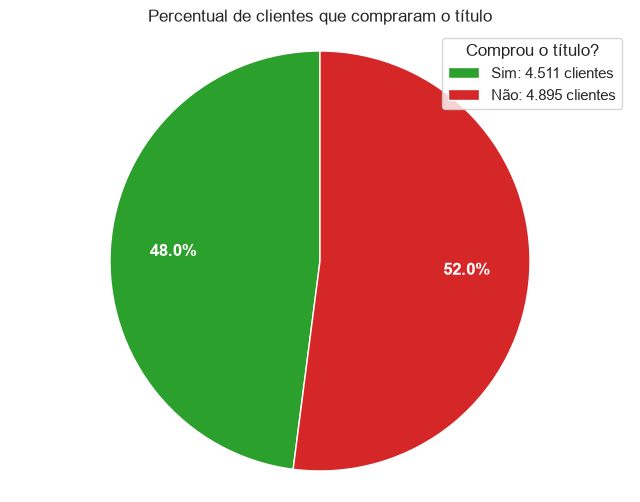

In [7]:
# Q1 - calculando o percentual de clientes que compraram o Título
print(df['Cliente_Comprou_o_Titulo?'].value_counts(normalize=True) * 100)

contagem = df['Cliente_Comprou_o_Titulo?'].value_counts().reindex(['Sim', 'Não'], fill_value=0)
percentual = contagem / contagem.sum() * 100

# Gráfico de barras para a variável alvo
fig, ax = plt.subplots(figsize=(8, 6))

cores = ["#2ca02c", "#d62728"]  # Sim: verde; Não: vermelho
fatias, _, _ = ax.pie(
    contagem,
    colors=cores,
    startangle=90,
    autopct="%1.1f%%",
    pctdistance=0.7,
    textprops={"color": "white", "weight": "bold"},
)

legenda = [
    f"{resposta}: {quantidade:,} clientes".replace(",", ".")
    for resposta, quantidade in contagem.items()
]
ax.legend(fatias, legenda, title="Comprou o título?", loc="best")
ax.set_title("Percentual de clientes que compraram o título")
ax.axis("equal")

plt.show()

R1) **48% dos clientes compraram o Título**, isso corresponde a 4511 clientes. Como não nos foi informado a taxa histórica de conversão, não conseguimos avaliar a eficácia dessa campanha. Podemos requisitar essa taxa para a área de negócio para fazer um estudo mais preciso.

,Frequência absoluta,Frequência relativa (%),Frequência acumulada (%)
Profissão,,,
Administrador,3289,34.967042,34.967042
Operário,1598,16.989156,51.956198
Técnico,1542,16.393791,68.349989
Serviços Gerais,769,8.175633,76.525622
Aposentado,672,7.144376,83.669998
Autônomo,344,3.657240,87.327238
Estudante,321,3.412715,90.739953
Desempregado,306,3.253243,93.993196
Empresário,269,2.859877,96.853073


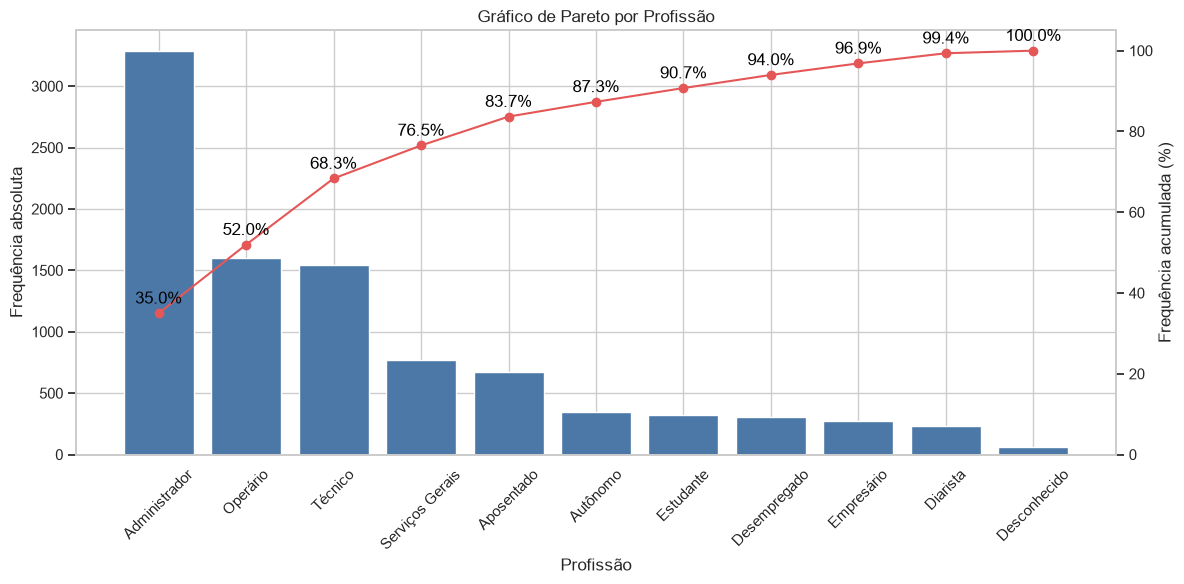

In [ ]:
# Q2 - quais profissões com maiores frequências são responsáveis por cerca de 80% da base?
frequencia_absoluta = df["Profissão"].value_counts()
frequencia_relativa = frequencia_absoluta / frequencia_absoluta.sum() * 100

tabela = pd.DataFrame({
    "Frequência absoluta": frequencia_absoluta,
    "Frequência relativa (%)": frequencia_relativa,
    
})

tabela["Frequência acumulada (%)"] = (
    tabela["Frequência relativa (%)"].cumsum()
)

display(tabela)

# Gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 6))


ax1.bar(
    tabela.index,
    tabela["Frequência absoluta"],
    color="#4C78A8"
)
ax1.set_xlabel("Profissão")
ax1.set_ylabel("Frequência absoluta")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    tabela.index,
    tabela["Frequência acumulada (%)"],
    color="#E45756",
    marker="o"
)
ax2.set_ylabel("Frequência acumulada (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)  # remove a grade do eixo secundário

# Rótulos pretos, com no máximo uma casa decimal
for x, valor in enumerate(tabela["Frequência acumulada (%)"]):
    ax2.annotate(
        f"{valor:.1f}%",
        (x, valor),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        color="black"
    )

ax1.set_title("Gráfico de Pareto por Profissão")
fig.tight_layout()
plt.show()

R2) As profissões **Administrado, Operário, Técnico, Serviços Gerais e Aposentado** representam 83,7% da base de clientes.

In [9]:
# Q3 - pode-se afirmar que 66% dos clientes não possuem ensino superior?
ensino_superior = df["Formação"].value_counts(normalize=True) * 100
ensino_superior

Formação
Ensino Médio       48.851797
Ensino Superior    33.244737
Fundamental        13.225601
Desconhecido        4.677865
Name: proportion, dtype: float64

R3) O percentual de clientes sem Ensino Superior é de **pelo menos 62,1% e pode chegar a 66,8%**, dependendo da escolaridade dos clientes classificados como “Desconhecido”. Portanto, como não sabemos a formação desse grupo, **não é possível afirmar que 66% dos clientes não possuem Ensino Superior.**

# 3. Análise de Conversão

O próximo passo será realizar uma **análise de associação** entre a variável `Cliente_Comprou_o_Titulo?` — que indica se o cliente comprou ou não comprou o título — e cada uma das demais variáveis. O objetivo é explorar quais características apresentam maior poder de distinção entre os clientes que compraram e os que não compraram.

Para isso, começaremos pelas variáveis numéricas, agrupando seus valores em faixas. Em seguida, organizaremos as variáveis em categorias e faixas e calcularemos as frequências de clientes que compraram e que não compraram em cada grupo.

In [10]:
# Discretizando as Variáveis Numéricas
df['Faixa_Idade'] = pd.cut(df['Idade'], bins=[0, 25, 35, 45, 55, 65, np.inf], labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66+'])
df['Faixa_Saldo'] = pd.cut(df['Saldo_Conta_Corrente'], bins=[-np.inf, 499, 1499, 4999, np.inf], labels=['0-499', '500-1499', '1500-4999', '5k+'])
df['Faixa_Qtd_Ligações'] = pd.cut(df['Qte_de_Ligações_Feitas'], bins=[0, 1, 2, 3, 4, float("inf")], labels=['1', '2', '3', '4', '5+'], right=True)

## 3.1 Information Value (IV)

O **Information Value (IV)** atua como uma medida exploratória para comparar o poder de separação de cada variável em relação à resposta. Para cada categoria *i* da variável, calcula-se o WoE (***Weight of Evidence***) e a contribuição parcial ao IV. Ele é calculado a partir de:

$$
\mathrm{IV} = \sum_i \left(\%\,\mathrm{Não}_i - \%\,\mathrm{Sim}_i\right)\times \mathrm{WoE}_i
$$

Nesta análise, o WoE é calculado como o logaritmo natural da proporção entre clientes que não compraram o produto (**%NonEvent**) em relação à proporção dos que compraram (**%Event**), em cada categoria:

$$
\mathrm{WoE}_i = \ln\left(\frac{\%\,\mathrm{Não}_i}{\%\,\mathrm{Sim}_i}\right)
$$

onde:
- **% Nãoᵢ**: proporção dos clientes que **não contrataram** o produto e pertencem à categoria *i*.
- **% Simᵢ**: proporção dos clientes que **contrataram** o produto e pertencem à categoria *i*.

Os valores de IV foram interpretados de forma aproximada segundo as faixas abaixo:
| Faixa de IV | Interpretação |
|:---:|:---:|
| < 0,02 | Muito fraco |
| Entre 0,02 e 0,10 | Fraco |
| Entre 0,10 e 0,30 | Médio |
| Entre 0,30 e 0,50 | Forte |
| Maior que 0,50 | Suspeito ou muito alto; recomenda-se verificar |


Para realizar os cálculos, importamos a classe **AnaliseIV** do módulo `src/analise_IV.py`. O método `get_iv_list()` retorna as variáveis ordenadas por IV decrescente, acompanhadas de sua classificação. Já o método `get_freq_table()` apresenta, para cada categoria da variável, as frequências observadas, os percentuais de “Não” e “Sim”, os valores de WoE e as contribuições parciais ao IV. Assim, podemos comparar as variáveis e examinar como cada categoria contribui para sua capacidade de separação.

> **Nota:**
> Quando uma categoria não possui observações em uma das classes (“Sim” ou “Não”), a implementação adiciona uma **correção de 0,5** às contagens dessa categoria para calcular o WoE e o IV. As frequências e os percentuais apresentados na tabela permanecem baseados nas contagens observadas.

In [11]:
from src.analise_IV import AnaliseIV

use_cols = ['Profissão','Formação','Estado_Civil','Faixa_Idade','Faixa_Saldo','Faixa_Qtd_Ligações','Cliente_Devedor?','Tem_Hipoteca?', 'Tem_Emprestimo?']

analise_iv = AnaliseIV(
    df=df,
    use_cols=use_cols,
    target='Cliente_Comprou_o_Titulo?'
)

display(analise_iv.get_iv_list())

,IV,Classificação
Variável,,
Tem_Hipoteca?,0.1706,Médio
Faixa_Idade,0.1410,Médio
Profissão,0.1395,Médio
Faixa_Qtd_Ligações,0.0686,Fraco
Faixa_Saldo,0.0577,Fraco
Tem_Emprestimo?,0.0509,Fraco
Formação,0.0412,Fraco
Estado_Civil,0.0344,Fraco
Cliente_Devedor?,0.0058,Muito fraco


### 3.1.1 Análise do Poder Discriminatório das Variáveis — *Information Value*

A análise de ***Information Value (IV)*** identificou diferenças no poder discriminatório das características dos clientes em relação à contratação do produto de investimento.

As variáveis **Hipoteca (IV = 0,1706)**, **Faixa Etária (IV = 0,1410)** e **Profissão (IV = 0,1395)** apresentaram os maiores valores, **sendo classificadas com poder discriminatório moderado**. Esses resultados indicam que as distribuições dessas características diferem entre os clientes que contrataram e aqueles que não contrataram o produto.

As variáveis **Quantidade de Ligações, Saldo Bancário, Empréstimo, Formação e Estado Civil** apresentaram baixo poder discriminatório individual, enquanto a condição de inadimplência (Cliente_Devedor?) demonstrou capacidade discriminatória praticamente inexistente (IV = 0,0058).

De modo geral, **nenhuma das variáveis analisadas apresentou poder discriminatório forte isoladamente**, sugerindo a necessidade de investigar a combinação de características para compreender melhor os padrões de contratação.

Vale ressaltar que **o IV não informa diretamente a direção da associação, nem demonstra causalidade**. Dessa forma, **não podemos descartar uma variável da composição do perfil de um cliente apenas por seu fator discriminante ser fraco ou inexistente**. Recomenda-se aprofundar a análise das categorias por meio do Weight of Evidence (WoE), das frequências e das taxas de contratação, buscando identificar os segmentos de clientes com maior propensão observada à aquisição do produto.

Esses resultados poderão subsidiar a definição de estratégias de segmentação e direcionamento das próximas campanhas de marketing.

> **Nota:**
> É fundamental levar em consideração o **número de observações em cada categoria**, pois isso resulta em uma maior ou menor **confiança na estimativa da frenquência** obtida (teoria frequentista).

In [12]:
# Frequência das Variáveis Categóricas
for coluna in analise_iv.use_cols:
    print(f"\n### {coluna}")
    display(analise_iv.get_freq_table(coluna))


### Profissão


col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
Profissão,,,,,,,,,
Administrador,1623,1666,3289,34.97,33.16,36.93,50.65,-0.1078,0.0041
Aposentado,226,446,672,7.14,4.62,9.89,66.37,-0.7615,0.0401
Autônomo,187,157,344,3.66,3.82,3.48,45.64,0.0932,0.0003
Desconhecido,33,27,60,0.64,0.67,0.60,45.00,0.1190,0.0001
Desempregado,130,176,306,3.25,2.66,3.90,57.52,-0.3846,0.0048
Diarista,141,95,236,2.51,2.88,2.11,40.25,0.3132,0.0024
Empresário,175,94,269,2.86,3.58,2.08,34.94,0.5398,0.0080
Estudante,86,235,321,3.41,1.76,5.21,73.21,-1.0869,0.0375
Operário,1001,597,1598,16.99,20.45,13.23,37.36,0.4351,0.0314



### Formação


col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
Formação,,,,,,,,,
Desconhecido,209,231,440,4.68,4.27,5.12,52.50,-0.1818,0.0015
Ensino Médio,2524,2071,4595,48.85,51.56,45.91,45.07,0.1161,0.0066
Ensino Superior,1426,1701,3127,33.24,29.13,37.71,54.40,-0.2580,0.0221
Fundamental,736,508,1244,13.23,15.04,11.26,40.84,0.2891,0.0109
Total,4895,4511,9406,100.00,100.00,100.00,47.96,NaN,0.0412



### Estado_Civil


col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
Estado_Civil,,,,,,,,,
Casado,2970,2344,5314,56.50,60.67,51.96,44.11,0.1550,0.0135
Divorciado,528,510,1038,11.04,10.79,11.31,49.13,-0.0470,0.0002
Solteiro,1397,1657,3054,32.47,28.54,36.73,54.26,-0.2524,0.0207
Total,4895,4511,9406,100.00,100.00,100.00,47.96,NaN,0.0344


... (8 outputs left out)


### Tem_Hipoteca?


col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
Tem_Hipoteca?,,,,,,,,,
Não,2140,2894,5034,53.52,43.72,64.15,57.49,-0.3835,0.0784
Sim,2755,1617,4372,46.48,56.28,35.85,36.99,0.4511,0.0922
Total,4895,4511,9406,100.00,100.00,100.00,47.96,NaN,0.1706



### Tem_Emprestimo?


col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
Tem_Emprestimo?,,,,,,,,,
Não,4144,4142,8286,88.09,84.66,91.82,49.99,-0.0812,0.0058
Sim,751,369,1120,11.91,15.34,8.18,32.95,0.6289,0.0450
Total,4895,4511,9406,100.00,100.00,100.00,47.96,NaN,0.0509


Antes de escrever as conclusões é importante explicar uma diferença entre `% Sim` e `Taxa Evento` contidas nas tabelas de frequências geradas pelo `get_freq_table()`.

- **Percentual de Eventos (% Sim)**: Representa a participação de cada categoria no total de eventos observados na base de dados.

    $$
    \%Sim_i = \frac{Sim_i}{\sum_i Sim_i} \times 100
    $$

    Responde:***"Do total de clientes que compraram o Título, qual percentual pertence a essa categoria?"***

- **Taxa de Eventos**: Representa a proporção de eventos observados dentro de uma determinada categoria.

    $$
    TaxaEvento_i = \frac{Sim_i}{Total_i} \times 100
    $$

    Responde: ***"Entre os clientes desta categoria, qual percentual comprou o produto?"***

#### 3.1.1.1 A relação entre Idade e Compra do Título não é Linear

Existe um comportamento semelhante a uma **curva em U**:
- Clientes de 18 a 25 anos apresentam taxa de contratação de 70,96%.
- Entre 36 e 55 anos, a taxa cai para aproximadamente 41,7%.
- A partir dos 56 anos, volta a crescer, chegando a 79,08% entre clientes com 66 anos ou mais.
Isso sugere que os clientes mais jovens e os mais idosos apresentam maior receptividade observada à oferta.

Entretanto, os motivos podem ser bastante diferentes. **Jovens podem estar iniciando sua jornada de investimentos, enquanto idosos podem estar interessados em preservar patrimônio ou obter rendimentos**. Essas são hipóteses de negócio, não conclusões demonstradas pelos dados.

**Outro detalhe**: a faixa de 66+ possui apenas 349 clientes. Portanto, embora a taxa seja elevada, esse segmento representa somente 3,71% da amostra, o que implica uma menor confiança ao inferir a taxa de compra para esta faixa.

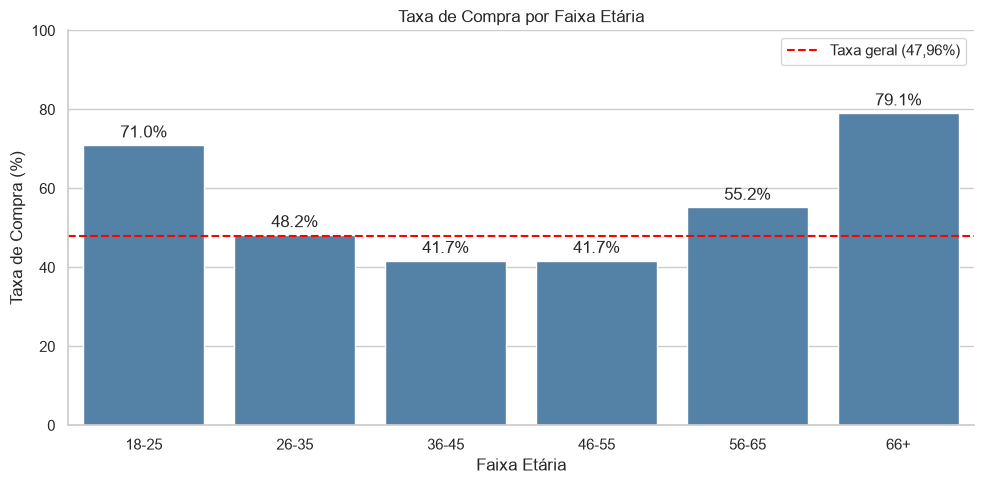

In [13]:
tabela_idade = analise_iv.get_freq_table('Faixa_Idade')
plot = tabela_idade.drop(index='Total')

# Gráfico de barras para a variável Faixa_Idade
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot,
    x=plot.index,
    y="Taxa Evento (%)",
    color="steelblue",
    ax=ax
)

ax.axhline(
    y=47.96,
    color="red",
    linestyle="--",
    label="Taxa geral (47,96%)"
)

ax.set(
    title="Taxa de Compra por Faixa Etária",
    xlabel="Faixa Etária",
    ylabel="Taxa de Compra (%)",
    ylim=(0, 100)
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

#### 3.1.1.2 Estudantes e Aposentados apresentam taxas surpreendentemente elevadas

A análise da variável Profissão revelou um poder discriminatório moderado (IV = 0,1395) em relação à contratação do título bancário. 

A Análise de Pareto identificou que **Administradores, Operários, Técnicos, Serviços Gerais e Aposentados** concentram aproximadamente 83,7% da base de clientes. Entretanto, a análise das taxas de contratação e do Weight of Evidence (WoE) demonstrou que a representatividade dos segmentos **não está necessariamente associada a uma maior propensão observada à compra**.

Dois grupos chamam especialmente a atenção:

- **Estudantes**: apresentam a maior taxa de contratação por profissão, 73,21%, embora representem apenas 3,41% da amostra.
- **Aposentados**: apresentam taxa de 66,37%, também bastante superior à média.

|Profissão|	% da base|Taxa de compra|WoE|
|:---:|:---:|:---:|:---:|
|Administrador|	34,97%|50,65%|	−0,1078|
|Operário| 16,99%|	37,36%|	+0,4351|
|Técnico| 16,39%|	46,43%|	+0,0612|
|Serviços Gerais|	8,18%|	39,27%|+0,3542|
|Aposentado|	7,14%|	66,37%	|−0,7615|

>**Referência**: taxa geral de compra de 47,96%.

Observe que, entre as cinco profissões mais frequentes, apenas Administradores e Aposentados apresentam taxas de contratação superiores à média geral. Há quatro insights que chamam a atenção aqui:
1. **Os Administradores são o principal segmento em volume**: Os Administradores, que representam 34,97% da base, concentram o maior volume absoluto de contratações, embora apresentem um WoE relativamente próximo de zero (−0,1078), indicando poder discriminatório limitado para essa categoria. Eles constituem um segmento comercialmente importante principalmente pelo volume de clientes e contratações, e não por apresentar um poder discriminatório individual particularmente elevado.
2. **Os Aposentados apresentam o perfil mais promissor entre as cinco profissões**: Embora representem apenas 7,14% da base, esse grupo apresentaram uma taxa de conversão de 66,37%. Esse resultado é relevante porque esse grupo constituem um público prioritário para investigar ações comerciais segmentadas, especialmente considerando sua taxa de conversão elevada. Entretanto, seria importante verificar o quanto dessa associação é explicado pela idade.
3. **Operários e Serviços Gerais representam uma parcela expressiva da base, mas apresentam menor conversão**: Esses segmentos concentram uma quantidade expressiva de clientes, mas apresentam menor receptividade observada à oferta. Seria interessante investigar se o produto, as condições comerciais ou a abordagem utilizada são adequados às características desses públicos.
4. **Os Estudantes representam um possível potencial de conversão**: Os Estudantes apresentaram uma taxa de contratação muito superior à dos administradores, mas possuem uma participação muito menor na base. Vale a pena levantar um estudo a respeito do porque a campanha ter sido tão atrativa para esse público.



#### 3.1.1.3 O padrão mais interessante: idade e profissão parecem contar a mesma história

| Categoria | WoE | Taxa de compra |
|:---:|:---:|:---:|
|Idade 66+	|−1,4116	|79,08%|
|Estudante|	−1,0869|	73,21%|
|Idade 18–25|	−0,9751	|70,96%|
|Aposentado|	−0,7615|	66,37%|

**Existe uma possível conexão entre essas categorias**. Os estudante podem estar concentrados nas faixas etárias mais jovens, enquanto os aposentados provavelmente estão mais presentes nas faixas etárias elevadas.

Isso levanta uma hipótese importante: **parte do poder discriminatório da profissão pode estar associado à estrutura etária dos clientes.**

Para explorar essa hipótese vamos cruzar as variáveis **Faixa Idade x Profissão x Taxa de Compra** utilizando o `pd.crosstab()` do Pandas. A ideia aqui é construir uma matriz em que as **linhas representem as faixas etárias**, **as colunas representem as profissões** e os **valores representem o percentual de clientes que compraram o título bancário** em cada combinação.

Como nossa variável de interesse é uma variável binária, podemos calcular a proporção através da média na categoria:

$$
\text{Taxa de Compra}_{ij}=\frac{\text{Compradores}_{ij}}{\text{Total de Clientes}_{ij}}\times100
$$

In [14]:
taxa_compra = pd.crosstab(
    df['Faixa_Idade'],
    df['Profissão'],
    df['Cliente_Comprou_o_Titulo?'].apply(lambda x: 1 if x == 'Sim' else 0),
    aggfunc='mean'
).mul(100).round(2)

display(taxa_compra)

Profissão,Administrador,Aposentado,Autônomo,Desconhecido,Desempregado,Diarista,Empresário,Estudante,Operário,Serviços Gerais,Técnico
Faixa_Idade,,,,,,,,,,,
18-25,61.90,NaN,70.00,NaN,83.33,66.67,100.00,79.27,65.31,62.16,67.50
26-35,53.16,50.00,50.33,53.85,60.19,45.16,30.77,67.63,40.03,38.96,45.32
36-45,45.55,10.00,40.66,23.08,51.09,26.15,37.50,62.50,33.91,38.28,46.12
46-55,47.96,35.94,29.31,50.00,56.58,40.96,31.88,50.00,33.97,36.64,41.90
56-65,58.27,61.59,51.85,50.00,65.52,42.86,35.71,NaN,38.89,36.11,59.09
66+,75.00,79.15,100.00,50.00,NaN,83.33,NaN,NaN,NaN,0.00,100.00


Para melhorar a visualização plotaremos um **mapa de calor** (heatmap), ele permite uma identificação mais intuitiva. Vamos também adicionar um rótulo em cada categoria para indicar o número de observações resultante desse cruzamento de variáveis, isso nos permite analisar quais taxas de compras tendem a ser mais estáveis e confiáveis e quais não.

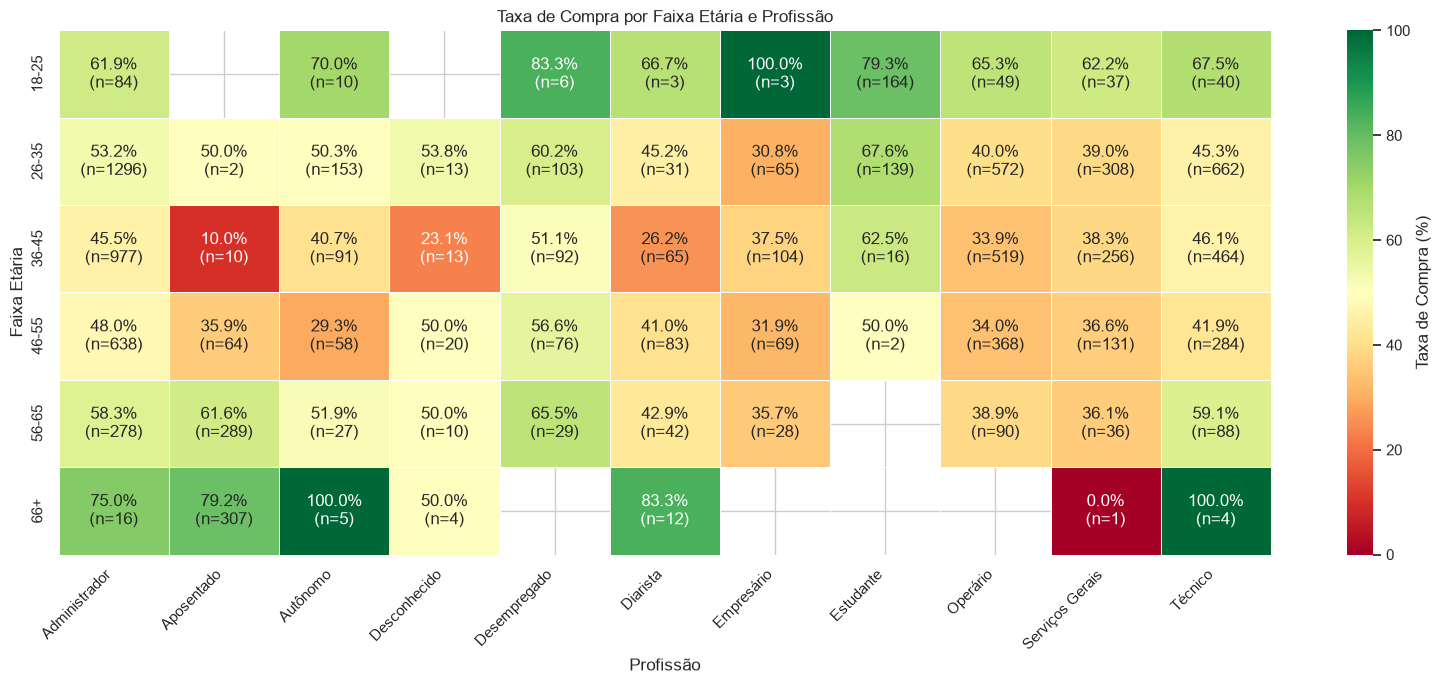

In [15]:
# Taxa de compra (%)
taxa = pd.crosstab(
    index=df["Faixa_Idade"],
    columns=df["Profissão"],
    values=df["Cliente_Comprou_o_Titulo?"].eq("Sim").astype(int),
    aggfunc="mean"
).mul(100)

# Quantidade de clientes
n = pd.crosstab(
    index=df["Faixa_Idade"],
    columns=df["Profissão"]
)

# Rótulos: taxa e quantidade
labels = taxa.copy().astype(object)

for i in range(taxa.shape[0]):
    for j in range(taxa.shape[1]):
        if pd.notna(taxa.iloc[i, j]):
            labels.iloc[i, j] = (
                f"{taxa.iloc[i, j]:.1f}%\n"
                f"(n={n.iloc[i, j]})"
            )
        else:
            labels.iloc[i, j] = ""

plt.figure(figsize=(16, 7))

sns.heatmap(
    taxa,
    annot=labels,
    fmt="",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Taxa de Compra (%)"}
)

plt.title("Taxa de Compra por Faixa Etária e Profissão")
plt.xlabel("Profissão")
plt.ylabel("Faixa Etária")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

A análise cruzada entre faixa etária e profissão revelou diferenças relevantes nas taxas de contratação do título bancário.

Observou-se que o comportamento de **maior contratação nas extremidades etárias**, identificado anteriormente, também aparece em **diferentes categorias profissionais**. Esse resultado sugere que a associação entre idade e contratação não é explicada exclusivamente pela composição profissional da base.

Adicionalmente, foram identificadas diferenças nas taxas de contratação entre profissões pertencentes à mesma faixa etária, sugerindo que **a ocupação profissional também pode contribuir para a diferenciação dos perfis de compradores**.

Destaca-se o comportamento dos aposentados, cuja elevada taxa de contratação agregada pode estar parcialmente relacionada à concentração de clientes nas faixas etárias mais avançadas (cerca de 88% das observações a partir de 66 anos são aposentados).

Entretanto, algumas combinações apresentaram taxas extremas, próximas de 0% ou 100%, exigindo a avaliação do tamanho amostral antes da formulação de conclusões.

De modo geral, os resultados sugerem que **idade e profissão apresentam associações potencialmente complementares** com a contratação do título bancário, justificando análises adicionais para investigar possíveis efeitos de confusão e interações entre essas características.

#### 3.1.1.4 A existência de hipoteca é o principal fator discriminatório individual

- Sem hipoteca: 57,49% (2.894 contratações)
- Com hipoteca: 36,99% (1.617 contratações)

A diferença é de **20,5 pontos percentuais**. É uma diferença expressiva, especialmente porque os dois grupos possuem tamanhos relevantes: **5.034 clientes sem hipoteca** e **4.372 clientes com hipoteca**.

Uma hipótese plausível é que **clientes com compromissos financeiros imobiliários tenham menor disponibilidade para realizar investimentos**. A ausência de hipoteca parece ser um critério promissor para investigar estratégias de segmentação, mas não podemos estabelecer causalidade com essa análise.

#### 3.1.1.5 A quantidade de ligações apresenta uma relação inversa com a compra do Título

A taxa de contratação cai de 53,20% para 32,14% entre clientes que receberam uma ligação e aqueles que receberam cinco ou mais. **Isso representa uma diferença de 21,06 pontos percentuais**. Esse resultado merece atenção porque pode indicar que clientes menos receptivos exigem mais tentativas de contato.Mas existe uma outra hipótese: **a quantidade de ligações pode ser consequência da dificuldade de conversão, e não sua causa.** 

Uma pergunta que merece investigação é ***"Será que compensa incodomodar tanto o cliente para vender Título?"***. Isso porque essa variável apresentou valores muito altos de quantidade de ligações feitas a um único cliente, chegando a um máximo de 63 ligações. Esse tipo de abordagem pode causar fricção e ocasionar um churn futuro.


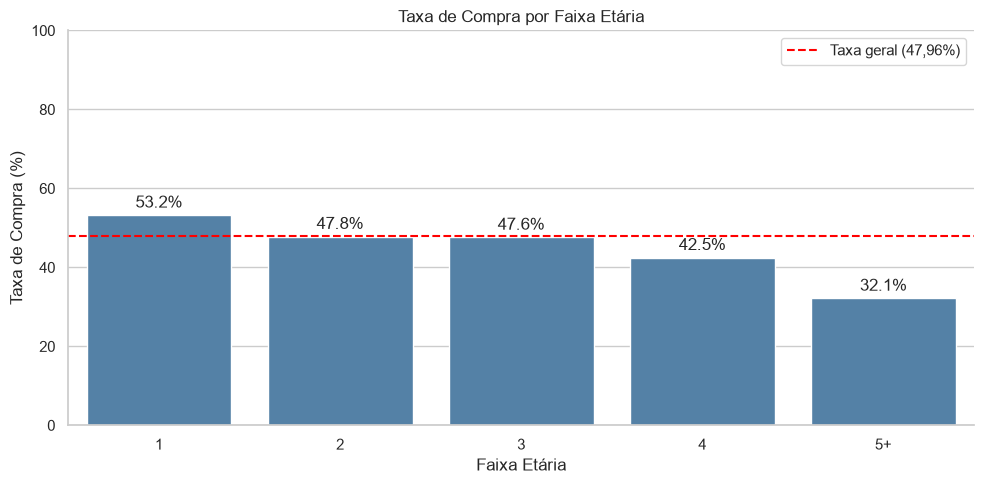

In [16]:
tabela_idade = analise_iv.get_freq_table('Faixa_Qtd_Ligações')
plot = tabela_idade.drop(index='Total')

# Gráfico de barras para a variável Faixa_Idade
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot,
    x=plot.index,
    y="Taxa Evento (%)",
    color="steelblue",
    ax=ax
)

ax.axhline(
    y=47.96,
    color="red",
    linestyle="--",
    label="Taxa geral (47,96%)"
)

ax.set(
    title="Taxa de Compra por Faixa Etária",
    xlabel="Faixa Etária",
    ylabel="Taxa de Compra (%)",
    ylim=(0, 100)
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

#### 3.1.1.6 O saldo bancário tem IV fraco, mas apresenta um padrão comercialmente relevante

| Saldo | Taxa de Compra |
|:---:|:---:|
| 0-499 | 41,80% |
| 500-1499 | 47,68% |
| 1500-4999 | 56,01% |
| 5000 ou mais | 55.86% |

Apesar de apresentar um IV de apenas 0,0577, um padrão interessante foi observado. **A taxa de compra aumenta conforme o saldo cresce até a faixa de 1500-4999, mas praticamente se estabiliza na faixa seguinte**. Isso sugere que pode existir uma associação positiva entre saldo e contratação, porém sem crescimento contínuo em todos os níveis. Vale ressaltar que a forma como os bins foram construídos pode ser o motivo causador dessa estabilização, uma vez que o Q3 dessa variável é 2.007 e varia até uma máximo de 29.340.

In [17]:
df['novo_bin_saldo'] =pd.cut(df['Saldo_Conta_Corrente'], bins=[-np.inf, 499, 1499, 4999, 9999, np.inf], labels=['0-499', '500-1499', '1500-4999', '5k-9999', '10k+'])

analise_iv_new = AnaliseIV(
    df=df,
    use_cols=["novo_bin_saldo"],
    target="Cliente_Comprou_o_Titulo?",
    event_value="Sim"
)

freq_table = analise_iv_new.get_freq_table("novo_bin_saldo")
display(freq_table)

col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
novo_bin_saldo,,,,,,,,,
0-499,2200,1580,3780,40.19,44.94,35.03,41.80,0.2493,0.0247
500-1499,1375,1253,2628,27.94,28.09,27.78,47.68,0.0112,0.0000
1500-4999,1000,1273,2273,24.17,20.43,28.22,56.01,-0.3231,0.0252
5k-9999,234,288,522,5.55,4.78,6.38,55.17,-0.2893,0.0046
10k+,86,117,203,2.16,1.76,2.59,57.64,-0.3895,0.0033
Total,4895,4511,9406,100.00,100.00,100.00,47.96,NaN,0.0578


A segunda binarização ajuda a investigar o patamar acima de R$ 5 mil, mas o resultado também mostra que o detalhamento dos cortes altera a leitura. Quando os grupos de R$ 5 mil a R$ 9.999 e R$ 10 mil ou mais são reunidos, a taxa é 55,86%; separados, ficam em 55,17% e 57,64%. A taxa agregada é uma média ponderada pelo número de clientes em cada faixa, por isso fica mais próxima da taxa do grupo maior. A separação é útil como exploração, mas **não basta para concluir que o corte em R$ 10 mil identifica uma mudança real de comportamento**.

Além disso, **o tamanho desses grupos pede cautela**. Na faixa de R$ 5 mil a R$ 9.999, 288 de 522 clientes compraram; na de R$ 10 mil ou mais, foram 117 de 203. Ainda que optassemos por construir uma estimativa intervalar, como o intervalo de confiança, para dar uma ideia da incerteza amostral, esses intervalos precisariam ser relativamente amplos (para uma confiança de 95%) por conta do número pequeno de amostra. É muito provável que esses dois intervalos estejam sobrepostos, o que reforça que **não há evidência clara, nesta análise, de crescimento a partir do aumento da faixa de saldo de conta corrente**.

Portanto, trataria **R$ 1.500 como um corte exploratório para segmentar a análise**. Nesta amostra, as taxas são menores nas faixas abaixo desse valor; a partir de R$ 1.500, são mais altas, embora não aumentem de forma contínua com o saldo.

#### 3.1.1.7 Os valores de WoE que mais chamam a atenção

Analisando especificamente a **magnitude e o sinal do WoE**, existem alguns resultados que merecem destaque, principalmente porque revelam comportamentos que o IV global não evidencia.

De modo geral, considera-se:
- **WoE negativo**: a categoria está proporcionalmente mais representada entre os clientes que compraram o título bancário.
- **WoE positivo**: a categoria está proporcionalmente mais representada entre os clientes que não compraram.
- **WoE próximo de zero**: a categoria apresenta distribuições semelhantes entre compradores e não compradores.

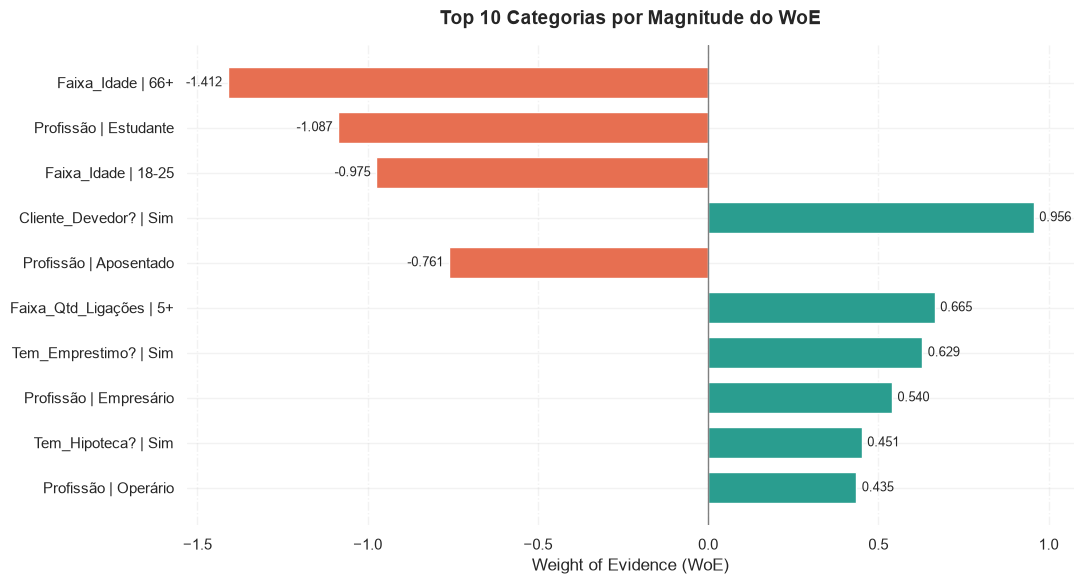

In [18]:
# Dicionário com as tabelas de frequência
freq_tables = {
    col: analise_iv.get_freq_table(col)
    for col in analise_iv.use_cols
}

# Consolidar WoE de todas as categorias
woe_df = pd.concat(
    [
        table.reset_index()
             .rename(columns={table.index.name or "index": "Categoria"})
             .assign(Variavel=col)
        for col, table in freq_tables.items()
    ],
    ignore_index=True
)

# Remover linhas de total e valores ausentes
woe_df = woe_df.loc[
    woe_df["WoE"].notna()
    & woe_df["Categoria"].astype(str).ne("Total")
].copy()

# Identificar as 10 maiores magnitudes de WoE
top_woe = (
    woe_df.assign(WoE_Abs=woe_df["WoE"].abs())
          .nlargest(10, "WoE_Abs")
          .sort_values("WoE_Abs", ascending=True)
          .copy()
)

# Criar rótulo combinando variável e categoria
top_woe["Label"] = (
    top_woe["Variavel"].astype(str)
    + " | "
    + top_woe["Categoria"].astype(str)
)

# Visualização
fig, ax = plt.subplots(figsize=(11, 6))

colors = [
    "#2A9D8F" if value > 0 else "#E76F51"
    for value in top_woe["WoE"]
]

bars = ax.barh(
    top_woe["Label"],
    top_woe["WoE"],
    color=colors,
    height=0.7
)

ax.axvline(0, color="gray", linewidth=1)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4,
    fontsize=9
)

ax.set_title(
    "Top 10 Categorias por Magnitude do WoE",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.set_xlabel("Weight of Evidence (WoE)")
ax.set_ylabel("")

ax.grid(axis="x", linestyle="-.", alpha=0.25)
ax.grid(axis="y", linestyle="-", alpha=0.25)
ax.set_axisbelow(True)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


**Conclusões:**

1. Clientes com mais de 66 anos apresentam o WoE de maior magnitude da análise (−1,4116), **indicando uma representação proporcional aproximadamente 4,10 vezes maior entre compradores do que entre não compradores**. A taxa de compra desse segmento é de 79,08%, significativamente superior à média geral de 47,96%.

2. A categoria de estudantes apresenta WoE de −1,0869 e uma taxa de compra de 73,21%, consideravelmente superior à média geral. Esse resultado sugere uma **associação relevante entre o perfil ocupacional e a aquisição do título bancário**.

3. Clientes devedores apresentam WoE de +0,9563, indicando maior representação proporcional entre os não compradores. Entretanto, essa categoria corresponde a apenas 0,69% da amostra, enquanto o IV global da variável é de apenas 0,0058.**Um WoE de elevada magnitude não implica necessariamente alto poder discriminatório global**. A baixa representatividade da categoria limita sua contribuição para o IV, reforçando a necessidade de interpretar WoE, IV e frequência conjuntamente.

4. Clientes que receberam cinco ou mais ligações apresentam WoE de +0,6655 e uma taxa de compra de apenas 32,14%, indicando maior representação proporcional entre os não compradores. Esse comportamento sugere uma associação negativa entre o volume elevado de contatos e a conversão. Entretanto, não é possível estabelecer causalidade: a necessidade de múltiplas ligações pode ser consequência da resistência inicial do cliente à oferta.

#### 3.1.1.8 A hipoteca apresenta um resultado particularmente consistente

| Hipoteca | WoE | Taxa de compra |
|:---:|:---:|:---:|
|Não |-0,3835 | 57,49%|
|Sim |+0,4511 |	36,99%|

O sinal muda de negativo para positivo, mostrando uma diferença clara na composição dos compradores e não compradores. Além disso, os dois grupos apresentam frequências elevadas, o que torna esse resultado especialmente relevante para a segmentação. Diferente de categorias muito pequenas, como clientes devedores, a associação observada para hipoteca envolve uma parcela expressiva da amostra.

# 4. Identificando o Perfil dos Clientes

Nesta seção, serão exploradas características dos clientes alcançados pela campanha e algumas de suas condições financeiras e de relacionamento com o banco. A análise será principalmente **univariada**, observando a distribuição das variáveis numéricas e as proporções das variáveis categóricas.

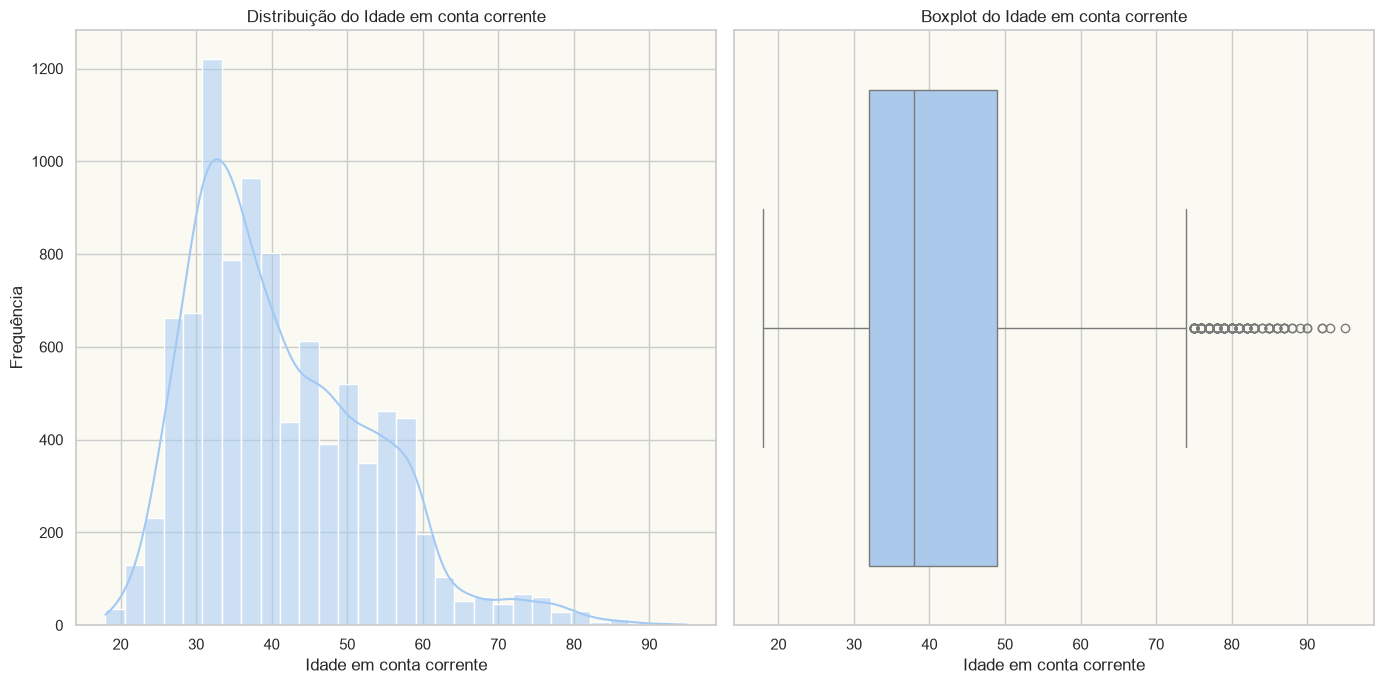


Estatísticas descritivas — Idade
────────────────────────────────────────────────────
Média:                 41.19
Desvio padrão:         12.03
Mínimo:                18.00
Q1 (25%):              32.00
Q2 / Mediana (50%):    38.00
Q3 (75%):              49.00
Máximo:                95.00
% de outliers:         1.58%


In [60]:
# Histograma + Boxplot - Idade
Idade = df['Idade'].dropna()

q1 = Idade.quantile(0.25)
q2 = Idade.quantile(0.50)
q3 = Idade.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = (Idade < limite_inferior) | (Idade > limite_superior)
percentual_outliers = outliers.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].set_facecolor('#FAF9F2')
axes[1].set_facecolor('#FAF9F2')

sns.histplot(
    data=df,
    x='Idade',
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Distribuição do Idade em conta corrente')
axes[0].set_xlabel('Idade em conta corrente')
axes[0].set_ylabel('Frequência')

sns.boxplot(
    data=df,
    x='Idade',
    ax=axes[1]
)
axes[1].set_title('Boxplot do Idade em conta corrente')
axes[1].set_xlabel('Idade em conta corrente')

plt.tight_layout()
plt.show()


print(
    f"\nEstatísticas descritivas — Idade\n"
    f"{'─' * 52}\n"
    f"Média:                 {Idade.mean():,.2f}\n"
    f"Desvio padrão:         {Idade.std():,.2f}\n"
    f"Mínimo:                {Idade.min():,.2f}\n"
    f"Q1 (25%):              {q1:,.2f}\n"
    f"Q2 / Mediana (50%):    {q2:,.2f}\n"
    f"Q3 (75%):              {q3:,.2f}\n"
    f"Máximo:                {Idade.max():,.2f}\n"
    f"% de outliers:         {percentual_outliers:.2f}%"
)

A campanha abordou clientes com idades entre 18 a 95 anos. Três informações relevantes podemos extrair:
- A **idade média é de 41 anos** e a mediana, 38 anos.
- Metade das pessoas tem **entre 32 e 49 anos** (intervalo interquartil de 17 anos).
- O **desvio padrão de 12,03** anos também aponta variação considerável em torno da média.

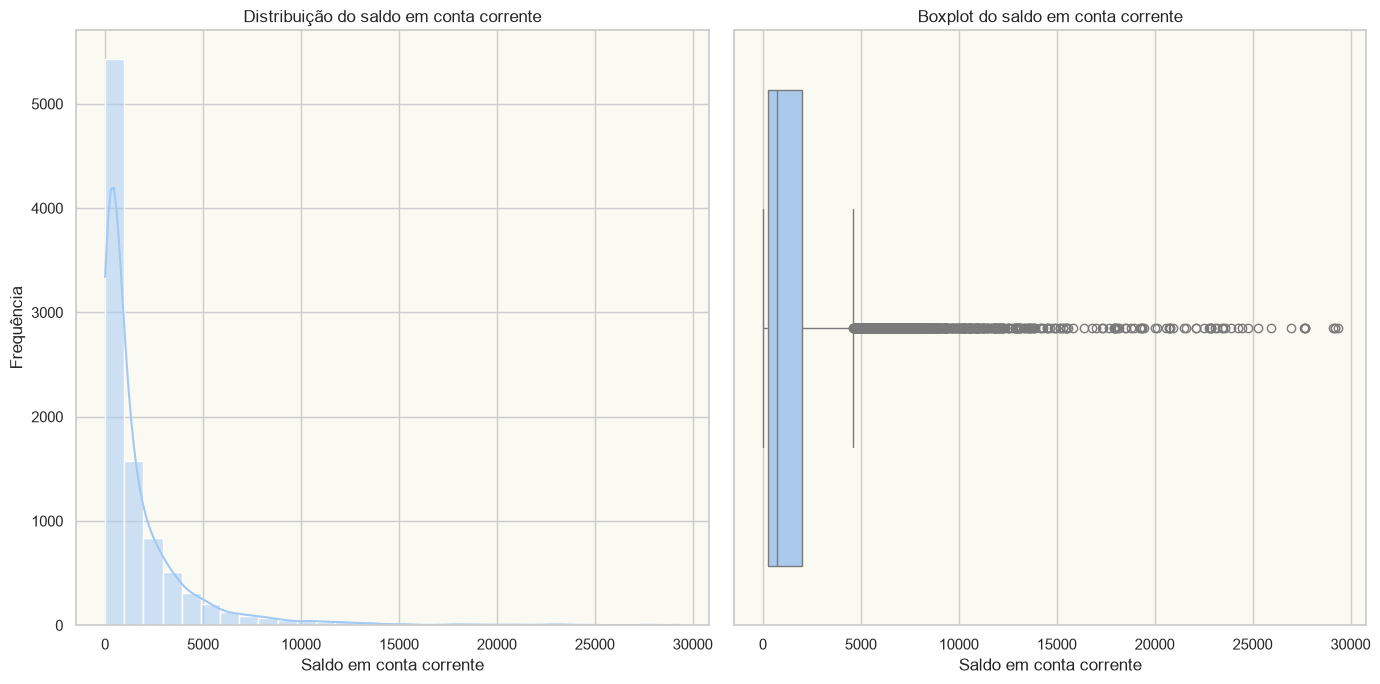


Estatísticas descritivas — Saldo_Conta_Corrente
────────────────────────────────────────────────────
Média:                 1,698.47
Desvio padrão:         2,731.62
Mínimo:                1.00
Q1 (25%):              257.00
Q2 / Mediana (50%):    726.00
Q3 (75%):              2,002.75
Máximo:                29,340.00
% de outliers:         8.91%


In [61]:
# Histograma + Boxplot da Varíavel "Saldo_Conta_Corrente"
saldo = df['Saldo_Conta_Corrente'].dropna()

q1 = saldo.quantile(0.25)
q2 = saldo.quantile(0.50)
q3 = saldo.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = (saldo < limite_inferior) | (saldo > limite_superior)
percentual_outliers = outliers.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].set_facecolor('#FAF9F2')
axes[1].set_facecolor('#FAF9F2')

sns.histplot(
    data=df,
    x='Saldo_Conta_Corrente',
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Distribuição do saldo em conta corrente')
axes[0].set_xlabel('Saldo em conta corrente')
axes[0].set_ylabel('Frequência')

sns.boxplot(
    data=df,
    x='Saldo_Conta_Corrente',
    ax=axes[1]
)
axes[1].set_title('Boxplot do saldo em conta corrente')
axes[1].set_xlabel('Saldo em conta corrente')

plt.tight_layout()
plt.show()

print(
    f"\nEstatísticas descritivas — Saldo_Conta_Corrente\n"
    f"{'─' * 52}\n"
    f"Média:                 {saldo.mean():,.2f}\n"
    f"Desvio padrão:         {saldo.std():,.2f}\n"
    f"Mínimo:                {saldo.min():,.2f}\n"
    f"Q1 (25%):              {q1:,.2f}\n"
    f"Q2 / Mediana (50%):    {q2:,.2f}\n"
    f"Q3 (75%):              {q3:,.2f}\n"
    f"Máximo:                {saldo.max():,.2f}\n"
    f"% de outliers:         {percentual_outliers:.2f}%"
)

A variável `Saldo_Conta_Corrente` apresenta uma distribuição **assimétrica à direita**. O saldo médio (1.698,47) é superior à mediana (726,00), e o máximo (29.340,00) está muito acima do terceiro quartil (Q3=2.002,75). Sendo assim, **a média não é um bom estimador para resumir essa variável** por ser uma medida de tendência central sensível a valores extremos.

**Metade dos clientes tem saldo entre 257,00 e 2.002,75**. O desvio padrão (2.731,62) é elevado em relação à média, indicando grande dispersão, provavelmente influenciada pelos valores mais altos. O mínimo de 1,00 mostra que há saldos baixos na base, embora os dados apresentados não indiquem se existem saldos nulos ou negativos.

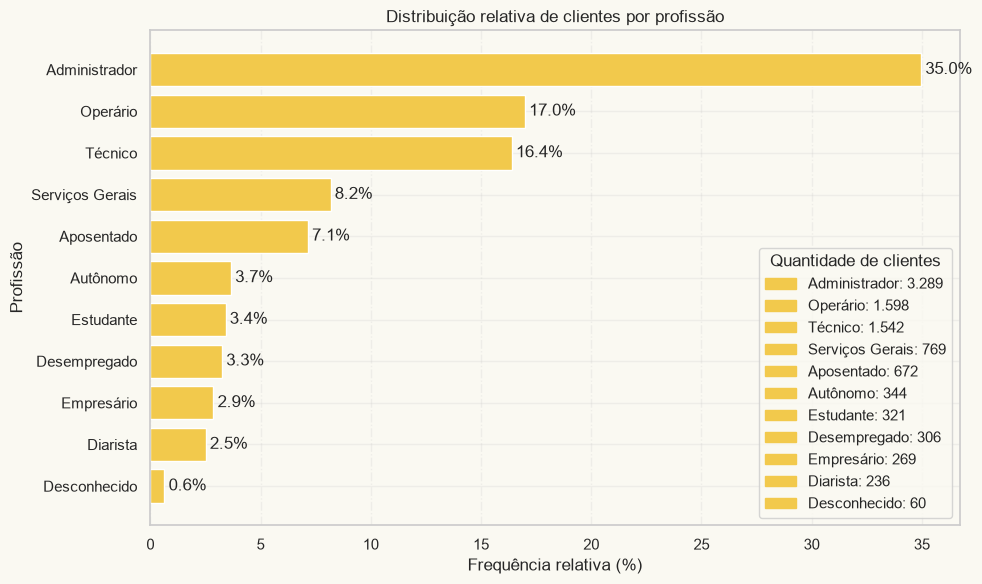

In [ ]:
# Gráfico de Barras Horizontais para as Profissões
frequencia_absoluta = df['Profissão'].value_counts().sort_values()
frequencia_relativa = frequencia_absoluta / frequencia_absoluta.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6), facecolor='#FAF9F2')
ax.set_facecolor('#FAF9F2')

barras = ax.barh(
    frequencia_relativa.index,
    frequencia_relativa.values,
    color='#F2C94C'
)

ax.bar_label(
    barras,
    labels=[f'{valor:.1f}%' for valor in frequencia_relativa.values],
    padding=3
)

# Itens independentes das barras: ordenados da maior para a menor quantidade
frequencia_legenda = frequencia_absoluta.sort_values(ascending=False)
handles_legenda = [
    plt.Rectangle((0, 0), 1, 1, color='#F2C94C')
    for _ in frequencia_legenda
]
rotulos_legenda = [
    f'{profissao}: {quantidade:,}'.replace(',', '.')
    for profissao, quantidade in frequencia_legenda.items()
]

ax.legend(
    handles_legenda,
    rotulos_legenda,
    title='Quantidade de Clientes',
    loc='lower right',
    frameon=True,
    facecolor='#FAF9F2'
)

ax.set_title('Distribuição relativa de Clientes por Profissão')
ax.set_xlabel('Frequência relativa (%)')
ax.set_ylabel('Profissão')

ax.grid(axis='x', linestyle='-.', alpha=0.25)
ax.grid(axis='y', linestyle='-', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

A base é composta principalmente por administradores (35%), seguidos por operários (17%) e técnicos (16,4%). **Essas três categorias somam cerca de 68,4% dos clientes**. As demais profissões aparecem com frequências menores; a categoria “Desconhecido” representa apenas 0,6%.

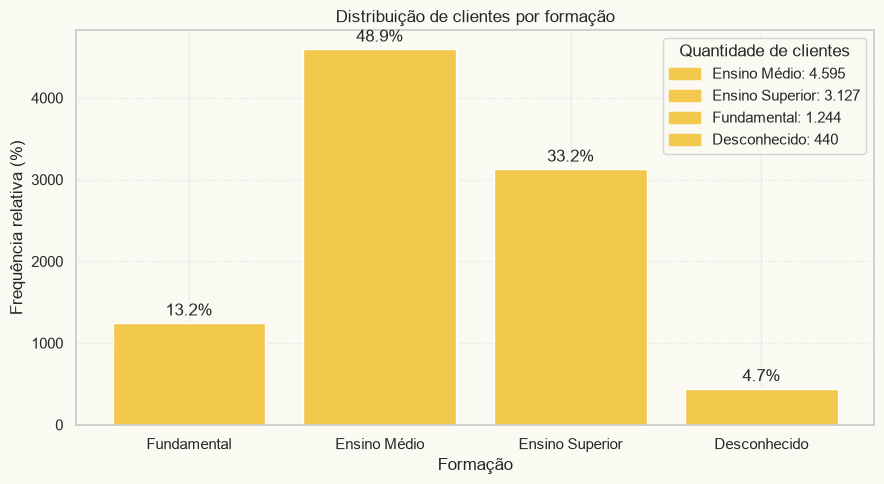

In [ ]:
# Gráfico de Barras para as Formações
ordem = ['Fundamental', 'Ensino Médio', 'Ensino Superior', 'Desconhecido']

frequencia_absoluta = df['Formação'].value_counts().reindex(ordem).fillna(0)
frequencia_relativa = frequencia_absoluta / frequencia_absoluta.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5), facecolor='#FAF9F2')
ax.set_facecolor('#FAF9F2')

barras = ax.bar(
    frequencia_absoluta.index,
    frequencia_absoluta.values,
    color='#F2C94C'
)

ax.bar_label(
    barras,
    labels=[f'{valor:.1f}%' for valor in frequencia_relativa.values],
    padding=3
)

# Legenda independente das barras, ordenada por quantidade decrescente
frequencia_legenda = frequencia_absoluta.sort_values(ascending=False)
handles_legenda = [
    plt.Rectangle((0, 0), 1, 1, color='#F2C94C')
    for _ in frequencia_legenda
]
rotulos_legenda = [
    f'{formacao}: {quantidade:,.0f}'.replace(',', '.')
    for formacao, quantidade in frequencia_legenda.items()
]

ax.legend(
    handles_legenda,
    rotulos_legenda,
    title='Quantidade de Clientes',
    loc='upper right',
    frameon=True,
    facecolor='#FAF9F2'
)

ax.set_title('Distribuição de Clientes por Formação')
ax.set_xlabel('Formação')
ax.set_ylabel('Frequência relativa (%)')

ax.grid(axis='y', linestyle='-.', alpha=0.25)
ax.grid(axis='x', linestyle='-', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Predominam clientes com **Ensino Médio (48,9%)**, seguidos por **Ensino Superior (33,2%)** e **Ensino Fundamental (13,2%)**. A formação é desconhecida para 4,7% dos clientes. Assim, a maior parte da base tem Ensino Médio ou Superior.

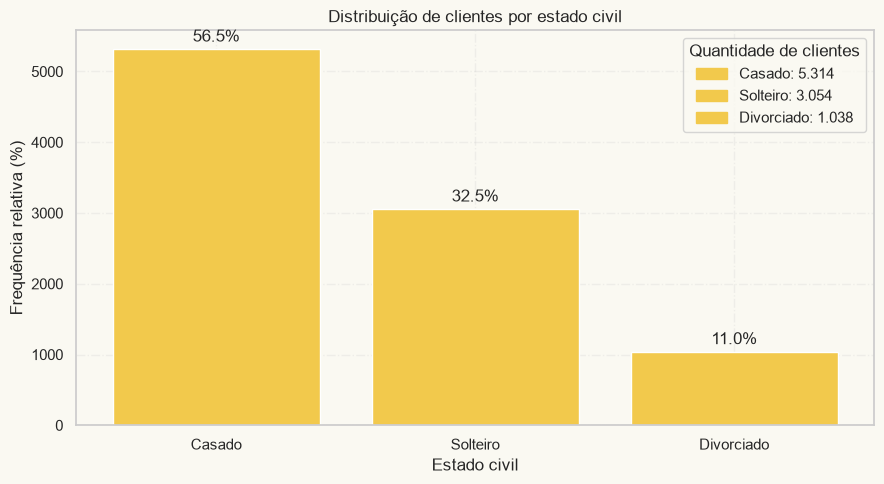

In [ ]:
# Gráfico de Barras para a Variável Estado Civil
frequencia_absoluta = df['Estado_Civil'].value_counts().sort_values(ascending=False)
frequencia_relativa = frequencia_absoluta / frequencia_absoluta.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5), facecolor='#FAF9F2')
ax.set_facecolor('#FAF9F2')

barras = ax.bar(
    frequencia_absoluta.index,
    frequencia_absoluta.values,
    color='#F2C94C'
)

ax.bar_label(
    barras,
    labels=[f'{valor:.1f}%' for valor in frequencia_relativa.values],
    padding=3
)

handles_legenda = [
    plt.Rectangle((0, 0), 1, 1, color='#F2C94C')
    for _ in frequencia_absoluta
]
rotulos_legenda = [
    f'{estado}: {quantidade:,}'.replace(',', '.')
    for estado, quantidade in frequencia_absoluta.items()
]

ax.legend(
    handles_legenda,
    rotulos_legenda,
    title='Quantidade de Clientes',
    loc='upper right',
    frameon=True,
    facecolor='#FAF9F2'
)

ax.set_title('Distribuição de Clientes por Estado Civil')
ax.set_xlabel('Estado Civil')
ax.set_ylabel('Frequência relativa (%)')

ax.grid(axis='y', linestyle='-.', alpha=0.25)
ax.grid(axis='x', linestyle='-.', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**A maioria dos clientes é casada (56,5%)**. Os solteiros representam 32,5% e os divorciados, 11%. A distribuição mostra uma concentração maior na categoria “Casado”.

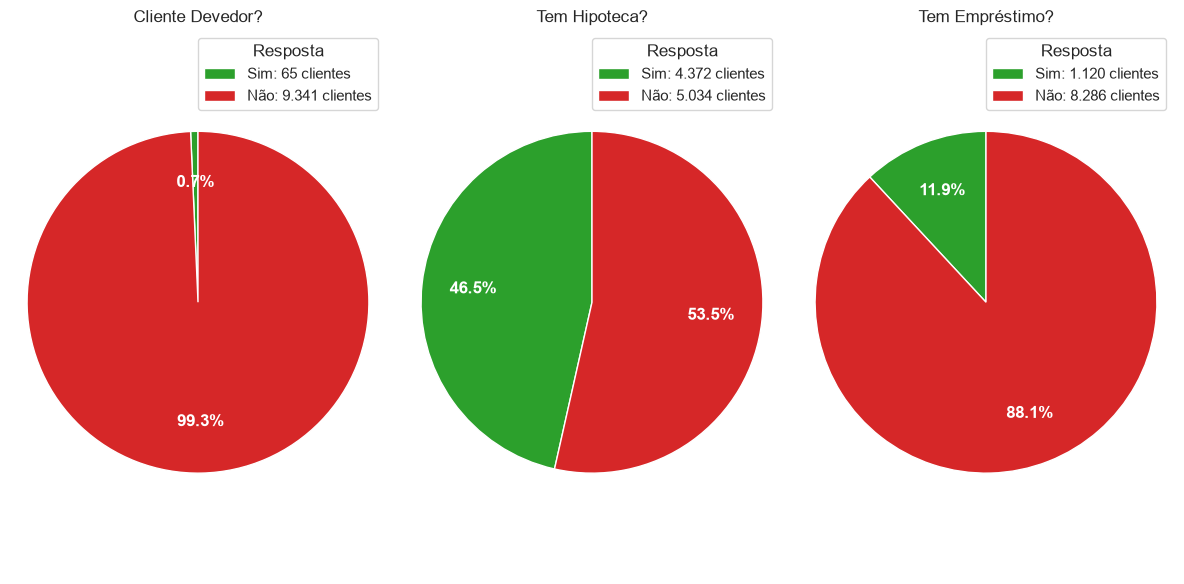

In [65]:
# Gráfico de Pizza para Variáveis Categóricas Binárias
cat_bin = ['Cliente_Devedor?', 'Tem_Hipoteca?', 'Tem_Emprestimo?']
titulos = ['Cliente Devedor?', 'Tem Hipoteca?', 'Tem Empréstimo?']
cores = ['#2ca02c', '#d62728']

fig, axes = plt.subplots(1, 3, figsize=(12, 6))
ax.set_facecolor('#FAF9F2')

for ax, variavel, titulo in zip(axes, cat_bin, titulos):
    contagem = (
        df[variavel]
        .value_counts()
        .reindex(['Sim', 'Não'], fill_value=0)
    )

    fatias, _, _ = ax.pie(
        contagem,
        colors=cores,
        startangle=90,
        autopct="%1.1f%%",
        pctdistance=0.7,
        textprops={"color": "white", "weight": "bold"},
    )

    legenda = [
        f"{resposta}: {quantidade:,} clientes".replace(",", ".")
        for resposta, quantidade in contagem.items()
    ]

    ax.legend(fatias, legenda, title="Resposta", loc="best")
    ax.set_title(titulo)
    ax.axis("equal")

plt.tight_layout()
plt.show()


Quase todos os clientes **não são devedores**: 99,3% responderam “Não”, enquanto 0,7% responderam “Sim”. Cerca de **46,5% têm hipoteca**, e **11,9% têm empréstimo pessoal**. Portanto, hipotecas são relativamente comuns na base, enquanto empréstimos pessoais são menos frequentes.

# 5. Indo Além... Outras Análises

## Quanto mais ligações, maior a conversão?

A quantidade de ligações realizadas durante a campanha chamou atenção na etapa de exploração dos dados. Embora 75% dos clientes tenham recebido até três ligações, foram observados 35 valores distintos para essa variável, com um **máximo de 63 ligações feitas a um único cliente**. Além disso, **1.036 dos 9.406 clientes receberam cinco ligações ou mais**, valor que eu considero alto o suficiente para gerar desconforto ao cliente e motivar um possível churn futuro.

A pergunta que orienta esta análise é: ***a taxa de conversão aumenta à medida que o número de ligações realizadas cresce?*** 

### O que já sabemos?
Já sabemos que a quantidade de ligações apresenta uma relação inversa com a compra do Título, como podemos observar na tabela abaixo:

| Faixa de ligações | Observações | Taxa de evento |
|---|---:|---:|
| 1 | 3.987 | 53,20% |
| 2 | 2.580 | 47,79% |
| 3 | 1.141 | 47,59% |
| 4 | 662 | 42,45% |
| 5+ | 1.036 | 32,14% |
| **Total** | **9.406** | **47,96%** |


O objetivo aqui é analisar como as probabilidade são influenciadas a partir da informação da quantidade de telefonemas realizados.

In [23]:
col_ligacoes = 'Qte_de_Ligações_Feitas'
col_compra = 'Cliente_Comprou_o_Titulo?'

# Considera somente linhas com informação disponível nas duas variáveis
dados = df[[col_ligacoes, col_compra]].dropna()

resultados = []

for minimo_ligacoes in range(2, 6):
    grupo = dados.loc[dados[col_ligacoes] >= minimo_ligacoes]

    tamanho_amostra = len(grupo)
    compras = grupo[col_compra].eq('Sim').sum()

    resultados.append({
        'Condição de ligações': f'{minimo_ligacoes} ou mais',
        'Clientes na amostra': tamanho_amostra,
        'Clientes que compraram': compras,
        'Probabilidade observada de compra': (
            compras / tamanho_amostra if tamanho_amostra > 0 else float('nan')
        )
    })


for maximo_ligacoes in range(2, 6):
    grupo = dados[
        dados[col_ligacoes] <= maximo_ligacoes
    ]

    tamanho_amostra = len(grupo)
    clientes_que_compraram = grupo[col_compra].eq('Sim').sum()

    resultados.append({
        'Condição de ligações': f'Até {maximo_ligacoes} ligações',
        'Clientes na amostra': tamanho_amostra,
        'Clientes que compraram': clientes_que_compraram,
        'Probabilidade observada de compra': (
            clientes_que_compraram / tamanho_amostra
            if tamanho_amostra > 0
            else float('nan')
        )
    })


tabela_probabilidades = pd.DataFrame(resultados).sort_values(by='Probabilidade observada de compra', ascending=False).reset_index(drop=True)

display(
    tabela_probabilidades.style.format({
        'Probabilidade observada de compra': '{:.2%}'
    })
)

,Condição de ligações,Clientes na amostra,Clientes que compraram,Probabilidade observada de compra
0,Até 2 ligações,6567,3354,51.07%
1,Até 3 ligações,7708,3897,50.56%
2,Até 4 ligações,8370,4178,49.92%
3,Até 5 ligações,8697,4301,49.45%
4,2 ou mais,5419,2390,44.10%
5,3 ou mais,2839,1157,40.75%
6,4 ou mais,1698,614,36.16%
7,5 ou mais,1036,333,32.14%


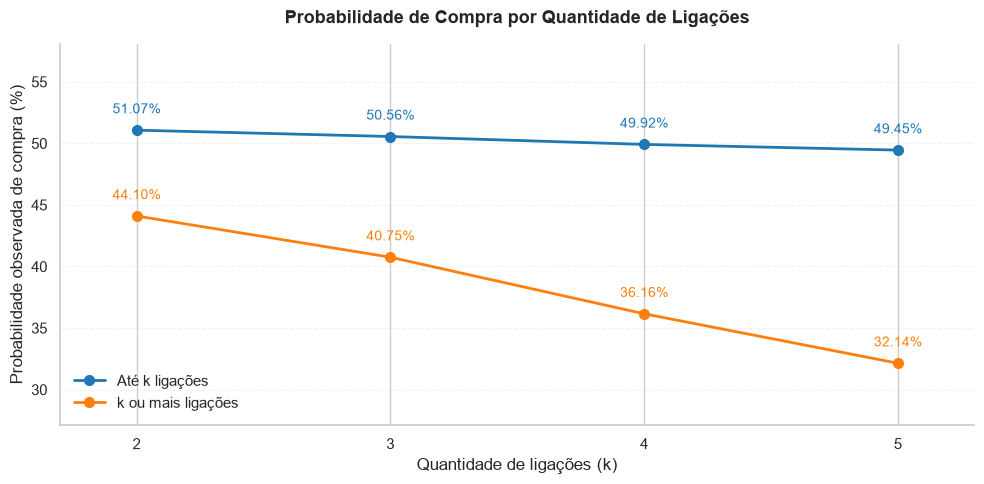

In [24]:
# Separar os grupos
ate_k = tabela_probabilidades.iloc[:4]
mais_k = tabela_probabilidades.iloc[4:]

col_prob = "Probabilidade observada de compra"

# Converter os valores para numéricos
def preparar_probabilidades(dados):
    y = pd.to_numeric(
        dados[col_prob].astype(str)
        .str.replace("%", "", regex=False)
        .str.replace(",", ".", regex=False),
        errors="raise"
    ).to_numpy(dtype=float)

    # Converter proporções para percentuais, se necessário
    if np.nanmax(y) <= 1:
        y = y * 100

    return y

x = np.array([2, 3, 4, 5])

y_ate = preparar_probabilidades(ate_k)
y_mais = preparar_probabilidades(mais_k)

# Configuração
fig, ax = plt.subplots(figsize=(10, 5))

# Plotar as linhas
for y, label, cor in [
    (y_ate, "Até k ligações", "tab:blue"),
    (y_mais, "k ou mais ligações", "tab:orange")
]:
    ax.plot(
        x, y,
        marker="o",
        linewidth=2,
        markersize=7,
        color=cor,
        label=label,
        zorder=3
    )

    # Adicionar rótulos
    for xi, yi in zip(x, y):
        ax.annotate(
            f"{yi:.2f}%",
            xy=(xi, yi),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            color=cor,
            annotation_clip=False,
            zorder=4
        )

# Formatação
ax.set_title(
    "Probabilidade de Compra por Quantidade de Ligações",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Quantidade de ligações (k)")
ax.set_ylabel("Probabilidade observada de compra (%)")

ax.set_xticks(x)
ax.set_xlim(1.7, 5.3)

# Ajustar limites considerando os rótulos
todos_valores = np.concatenate([y_ate, y_mais])
ax.set_ylim(
    max(0, todos_valores.min() - 5),
    todos_valores.max() + 7
)

# Grade
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25
)

ax.legend(frameon=False, loc="lower left")

# Remover bordas
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

A análise identificou uma associação negativa entre a quantidade de ligações realizadas durante a campanha e a probabilidade observada de compra do título bancário. Clientes que receberam apenas uma ligação apresentaram uma taxa de conversão de 53,20%, enquanto aqueles que receberam cinco ou mais ligações registraram apenas 32,14%, representando uma diferença de 21,06 pontos percentuais.

A análise das probabilidades condicionais reforça esse comportamento. Entre os clientes que receberam até duas ligações, a probabilidade observada de compra foi de 51,07%, enquanto aqueles que receberam três ou mais ligações, essa probabilidade caiu para 40,75%.

Embora os resultados indiquem uma associação consistente, não é possível estabelecer uma relação causal. Clientes com menor propensão à compra podem ter recebido mais tentativas de contato, e a própria conversão pode ter determinado a interrupção das ligações.

Três explicações possíveis para esse comportamento:

1. **Resistência prévia à compra**: clientes menos interessados podem exigir mais tentativas de contato.
2. **Interrupção após conversão**: clientes que compraram nas primeiras ligações possivelmente deixaram de receber novos contatos.
3. **Desgaste comercial**: o excesso de contatos pode gerar desconforto e reduzir o interesse pelo produto.

Um fato importante a ser considerado é se a campanha interrompe as ligações após a compra, a quantidade total de contatos é parcialmente determinada pelo próprio resultado da campanha. Isso introduz um problema de causalidade reversa. Além disso, o possível aumento do churn é uma hipótese de negócio relevante, mas não pode ser confirmado nesta análise. É importante levar essas três hipóteses para area de negócio validar antes de estabelecer qualquer relação causal.

## Podemos afirmar que a probabilidade de um novo cliente comprar um título é de 48%?

**Não exatamente.** Os 48% representam a proporção de compras observada na amostra analisada. Como não observamos todos os clientes do banco, esse resultado não garante que a taxa de compra da população, ou de novos clientes, seja exatamente 48%.

Para interpretar essa taxa como uma estimativa da população, assumimos que a amostra seja representativa, por exemplo, que os clientes tenham sido selecionados de forma aleatória e contemplem a diversidade de perfis e regiões. Mesmo sob essa premissa, estimativas calculadas a partir de amostras estão sujeitas à **incerteza amostral**. Por isso, é importante acompanhar a estimativa pontual com um intervalo que represente essa incerteza.

Para estimar o intervalo da proporção, utilizaremos o **intervalo de Wilson**:

$$
\frac{
\hat{p} + \frac{z^2}{2n}
\pm
z\sqrt{\frac{\hat{p}(1-\hat{p})}{n}+\frac{z^2}{4n^2}}
}{
1+\frac{z^2}{n}
}
$$

em que:

- $n$ é o número de clientes observados;
- $x$ é o número de clientes que compraram o título;
- $\hat{p} = x/n$ é a proporção observada;
- $z$ é o quantil da distribuição normal padrão correspondente ao nível de confiança. Para 95% de confiança, $z \approx 1{,}96$.

Para comparação, também calcularemos o **intervalo binomial exato de Clopper–Pearson**, construído para estimar uma proporção binomial. Além disso, testaremos uma aproximação baseada na distribuição *t* de Student. Como a variável de compra é binária, sua proporção corresponde à média dos valores codificados como 0 e 1. Com uma amostra grande como esta, o intervalo *t* pode servir como comparação; ainda assim, ele não considera diretamente a natureza discreta e limitada da proporção. Por isso, compararemos seus resultados com os métodos próprios para proporções.

In [25]:
# Dados observados
compras = 4511
n = 9406
nivel_confianca = 0.95

p_hat = compras / n
alpha = 1 - nivel_confianca
z = 1.959963984540054  # quantil normal para 95% de confiança


# Intervalo de Wilson
denominador = 1 + z**2 / n
centro = (p_hat + z**2 / (2 * n)) / denominador
margem = (
    z
    * sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
    / denominador
)
wilson = (centro - margem, centro + margem)


# Intervalo binomial exato de Clopper–Pearson
clopper_pearson = (
    beta.ppf(alpha / 2, compras, n - compras + 1),
    beta.ppf(1 - alpha / 2, compras + 1, n - compras),
)


# Intervalo t de Student aplicado aos indicadores binários (0 = não comprou, 1 = comprou)
gl = n - 1
desvio_padrao = sqrt(n / (n - 1) * p_hat * (1 - p_hat))
erro_padrao = desvio_padrao / sqrt(n)
t_critico = t.ppf(1 - alpha / 2, df=gl)
margem_t = t_critico * erro_padrao
intervalo_t = (p_hat - margem_t, p_hat + margem_t)


# Exibição dos resultados
intervalos = {
    "Wilson": wilson,
    "Clopper–Pearson": clopper_pearson,
    "t de Student": intervalo_t,
}

print(f"Clientes analisados: {n:,}".replace(",", "."))
print(f"Compras: {compras:,}".replace(",", "."))
print(f"Proporção observada: {p_hat:.2%}")
print(f"Nível de confiança: {nivel_confianca:.0%}\n")

print(f"{'Método':<22} {'Limite inferior':>17} {'Limite superior':>17} {'Largura':>12}")
print("-" * 72)

for metodo, (inferior, superior) in intervalos.items():
    print(
        f"{metodo:<22} "
        f"{inferior:>16.2%} "
        f"{superior:>16.2%} "
        f"{superior - inferior:>11.2%}"
    )

Clientes analisados: 9.406
Compras: 4.511
Proporção observada: 47.96%
Nível de confiança: 95%

Método                   Limite inferior   Limite superior      Largura
------------------------------------------------------------------------
Wilson                           46.95%           48.97%       2.02%
Clopper–Pearson                  46.94%           48.97%       2.03%
t de Student                     46.95%           48.97%       2.02%


Os três métodos produziram resultados praticamente iguais. Todos situam a taxa de compra **entre aproximadamente 46,9% e 49,0%**. A estimativa pontual é **47,96%**, e a largura dos intervalos fica em torno de 2,02 pontos percentuais — equivalente a cerca de ±1,01 de **margem de erro**.

Sob as premissas de amostragem do método, os dados são compatíveis com uma taxa populacional próxima de 47% a 49%, no nível de confiança de 95%. Isso não significa que haja 95% de probabilidade de a taxa estar nesse intervalo específico. Significa que, se repetíssemos muitas vezes o processo de amostragem e cálculo, aproximadamente 95% dos intervalos construídos dessa forma conteriam a verdadeira proporção populacional.

# 6. Como aprofundar a investigação?

Algumas questões ficaram em aberto durante a elaboração deste estudo por necessitarem de uma análise mais complexa. Eu recomendaria mais duas análises complementares:
- **Teste de tendência**: verificar estatisticamente se existe uma tendência negativa entre quantidade de ligações e conversão, utilizando, por exemplo, regressão logística.
- **Análise estratificada**: comparar a taxa de conversão por quantidade de ligações dentro de segmentos de idade, profissão e histórico de campanhas, reduzindo possíveis efeitos de confusão. Uma alternativa para essa análise seria aplicar um algoritmo de clusterização para identificar os melhores clusters e comparar com as hipóteses levantadas neste estudo.


# 7. Considerações Finais

Neste notebook, foram utilizadas técnicas de análise de dados para responder às perguntas específicas levantadas pela área de negócio e compreender melhor os resultados da campanha. A análise explorou o perfil dos clientes, a conversão observada e sua distribuição entre os grupos analisados.

O ***Information Value*** foi utilizado como medida exploratória para avaliar o potencial de separação entre clientes que compraram o título e aqueles que não compraram. Como complemento, estimou-se um intervalo de confiança para taxa de conversão, de modo a considerar a incerteza associada a essa estimativa.

Além disso, foi analisada a relação entre a **quantidade de ligações feitas durante o período da campanha e a conversão**, atualizando as probabilidades de conversão de forma condicional conforme o número de ligações feitas.

Os próximos passos consiste na elaboração de um **relatório técnico** ou **um dashboard informativo** para comunicar os principais achados neste notebook.